# Functional dimension of the trained networks

This notebook loads the networks that `train.ipynb` trained and stored, keeps those that count as trained (converged,
and better than the linear classifier on the test set), and computes the exact float64 Jacobian of the map from the
parameters to the logits, as `experiments.ipynb` does for random weights in Figures 1 and 4. Its rank on a large batch
of inputs is the functional dimension, read at the largest gap of the singular values.

Two batches of inputs, $1000$ each: inputs of the dataset, drawn from all three splits, and Gaussian inputs
$\mathcal N(0, I_p)$ in the standardized coordinates, as in the figures. On the dataset's inputs, a direction of the
input space that the batch does not span leaves $d_{\mathrm{model}}$ entries of the embedding without effect, so the
count there is lower by $d_{\mathrm{model}}(p - \operatorname{rank} X)$; for the datasets used here the batch spans the
whole input space, and this correction is zero.

Predicted ranks, as in the note: $P - g - s$ with skips and $P - (L+1)g - s$ without, where $g = d_{\mathrm{model}}^2$
without normalization and $d_{\mathrm{model}}(d_{\mathrm{model}}-1)/2$ under RMSNorm, and $s$ counts the rescalings of
hidden units (none for $\tanh$ and GELU, one per unit for SwiGLU, two for ReGLU). The skips should add $Lg$: $48$
without normalization and $18$ under RMSNorm.

The spectra are stored in `results/spectra_trained.npz` and computed only where that file lacks them.

In [1]:
import json, time
from collections import Counter
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp
import numpy as np, torch
import small_nets as sn

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)        # one thread per process; the workers below run in parallel
baselines = json.loads((sn.RESULTS / "baselines.json").read_text())
summary = json.loads((sn.RESULTS / "train_summary.json").read_text())
DATASETS = list(baselines)
ACTS, NORMS, KINDS = list(sn.ACTS), [None, 1e-5], ["skip", "noskip", "wide"]
runs = [r for r in summary if r["trained"]]
print(f"{len(runs)} of {len(summary)} stored networks count as trained and are analyzed")
NB = 1000
batches = {}
for name in DATASETS:
    ds = sn.load(name)
    Xall = np.vstack([ds[k][0] for k in ("train", "val", "test")])
    rng = np.random.default_rng(0)
    Xd = Xall[rng.choice(len(Xall), size=min(NB, len(Xall)), replace=False)]
    Xg = rng.standard_normal((NB, Xall.shape[1]))
    batches[name] = {"data": Xd, "gauss": Xg}
    print(f"{name:13s} p = {Xall.shape[1]}: rank of the data batch {np.linalg.matrix_rank(Xd)}, "
          f"of the Gaussian batch {np.linalg.matrix_rank(Xg)}")

436 of 480 stored networks count as trained and are analyzed


hypercube     p = 6: rank of the data batch 6, of the Gaussian batch 6
clusters      p = 8: rank of the data batch 8, of the Gaussian batch 8
satimage      p = 36: rank of the data batch 36, of the Gaussian batch 36
segmentation  p = 18: rank of the data batch 18, of the Gaussian batch 18


In [2]:
def key(r):
    norm = "none" if r["eps"] is None else "rms"
    return f"{r['dataset']}_{r['act']}_{norm}_{r['kind']}_s{r['seed']}"


def analyze(r):
    torch.set_num_threads(1)
    rec = torch.load(sn.RUNS / sn.run_name(r["dataset"], r["act"], r["eps"], r["kind"], r["lr"], r["seed"]),
                     weights_only=True)
    th, sh = rec["theta"], [tuple(s) for s in rec["shapes"]]
    out = {"P": th.numel()}
    for b, X in batches[r["dataset"]].items():
        s, rank, gap = sn.spectrum(th, X, r["act"], r["kind"] == "skip", r["eps"], sh)
        out[b] = (np.log10(np.maximum(s, 1e-300)).astype(np.float32), rank, gap)
    return key(r), out


path = sn.RESULTS / "spectra_trained.npz"
saved = dict(np.load(path)) if path.exists() else {}
todo = [r for r in runs if key(r) + "_data_rank" not in saved]
t0 = time.time()
with ProcessPoolExecutor(mp_context=mp.get_context("fork")) as ex:
    for k, out in ex.map(analyze, todo, chunksize=4):
        saved[k + "_P"] = np.array(out["P"])
        for b in ("data", "gauss"):
            ls, rank, gap = out[b]
            saved[f"{k}_{b}_logs"], saved[f"{k}_{b}_rank"], saved[f"{k}_{b}_gap"] = ls, np.array(rank), np.array(gap)
if todo:
    np.savez_compressed(path, **saved)
print(f"{len(todo)} networks analyzed in {time.time() - t0:.0f}s; {len(runs) - len(todo)} loaded from {path.name}")

0 networks analyzed in 0s; 436 loaded from spectra_trained.npz


In [3]:
# ranks against the counts
def predicted(r):
    P = int(saved[key(r) + "_P"])
    c = sn.count(r["kind"], r["act"], r["eps"], P, r["widths"])
    rank_X = int(np.linalg.matrix_rank(batches[r["dataset"]]["data"]))
    return P, int(c), int(c - sn.d * (baselines[r["dataset"]]["p"] - rank_X))


rows, agree = [], Counter()
for r in runs:
    P, c, c_data = predicted(r)
    for b, cb in (("data", c_data), ("gauss", c)):
        rk = int(saved[f"{key(r)}_{b}_rank"])
        agree[(b, rk == cb)] += 1
        rows.append(dict(dataset=r["dataset"], act=r["act"], eps=r["eps"], kind=r["kind"], seed=r["seed"], batch=b,
                         P=P, count=cb, rank=rk, gap=float(saved[f"{key(r)}_{b}_gap"])))
for b in ("data", "gauss"):
    n_ok, n_all = agree[(b, True)], agree[(b, True)] + agree[(b, False)]
    print(f"{'dataset' if b == 'data' else 'Gaussian'} inputs: rank at the largest gap equals the count in "
          f"{n_ok}/{n_all} trained networks")
(sn.RESULTS / "ranks_trained.json").write_text(json.dumps(rows, indent=1))

dataset inputs: rank at the largest gap equals the count in 398/436 trained networks
Gaussian inputs: rank at the largest gap equals the count in 398/436 trained networks


163879

In [4]:
# per dataset, activation and normalization: the ranks read in the seeds, and what the skips add
def ranks(name, act, eps, kind, b):
    return {x["seed"]: x["rank"] for x in rows if (x["dataset"], x["act"], x["eps"], x["kind"], x["batch"]) ==
            (name, act, eps, kind, b)}


for b in ("data", "gauss"):
    print(f"\n=== {'inputs of the dataset' if b == 'data' else 'Gaussian inputs'} ===")
    for name in DATASETS:
        print(f"\n{name}")
        for act in ACTS:
            for eps in NORMS:
                g = sn.group_dim(eps)
                cells = []
                for kind in KINDS:
                    rk = ranks(name, act, eps, kind, b)
                    cnt = [x["count"] for x in rows if (x["dataset"], x["act"], x["eps"], x["kind"], x["batch"]) ==
                           (name, act, eps, kind, b)]
                    seen = ", ".join(f"{v} in {c}" for v, c in sorted(Counter(rk.values()).items()))
                    cells.append(f"{kind} {seen} (count {cnt[0] if cnt else '-'})")
                r1, r0 = ranks(name, act, eps, "skip", b), ranks(name, act, eps, "noskip", b)
                gains = [r1[s] - r0[s] for s in sorted(set(r1) & set(r0))]
                add = ", ".join(f"{v} in {c}" for v, c in sorted(Counter(gains).items()))
                norm = "none" if eps is None else "RMSNorm"
                print(f"  {act:6s} {norm:7s} | " + " | ".join(cells) + f" | skips add {add} (L g = {sn.L * g})")


=== inputs of the dataset ===

hypercube
  tanh   none    | skip 216 in 5 (count 216) | noskip 168 in 5 (count 168) | wide 216 in 5 (count 216) | skips add 48 in 5 (L g = 48)
  tanh   RMSNorm | skip 226 in 5 (count 226) | noskip 208 in 5 (count 208) | wide 232 in 5 (count 232) | skips add 18 in 5 (L g = 18)
  GELU   none    | skip 216 in 5 (count 216) | noskip 168 in 5 (count 168) | wide 216 in 5 (count 216) | skips add 48 in 5 (L g = 48)
  GELU   RMSNorm | skip 226 in 5 (count 226) | noskip 208 in 5 (count 208) | wide 232 in 5 (count 232) | skips add 18 in 5 (L g = 18)
  ReGLU  none    | skip 264 in 5 (count 264) | noskip 216 in 3 (count 216) | wide 256 in 4 (count 256) | skips add 48 in 3 (L g = 48)
  ReGLU  RMSNorm | skip 274 in 5 (count 274) | noskip 225 in 2, 235 in 3 (count 256) | wide 255 in 5 (count 276) | skips add 39 in 3, 49 in 2 (L g = 18)
  SwiGLU none    | skip 288 in 5 (count 288) | noskip 240 in 5 (count 240) | wide 284 in 5 (count 284) | skips add 48 in 5 (L g = 48)
 

wrote /home/claude/skips_fix_gauges/trained/results/figs/spectra_trained_gelu.pdf


wrote /home/claude/skips_fix_gauges/trained/results/figs/spectra_trained_hypercube.pdf


wrote /home/claude/skips_fix_gauges/trained/results/figs/spectra_trained_clusters.pdf


wrote /home/claude/skips_fix_gauges/trained/results/figs/spectra_trained_satimage.pdf


wrote /home/claude/skips_fix_gauges/trained/results/figs/spectra_trained_segmentation.pdf


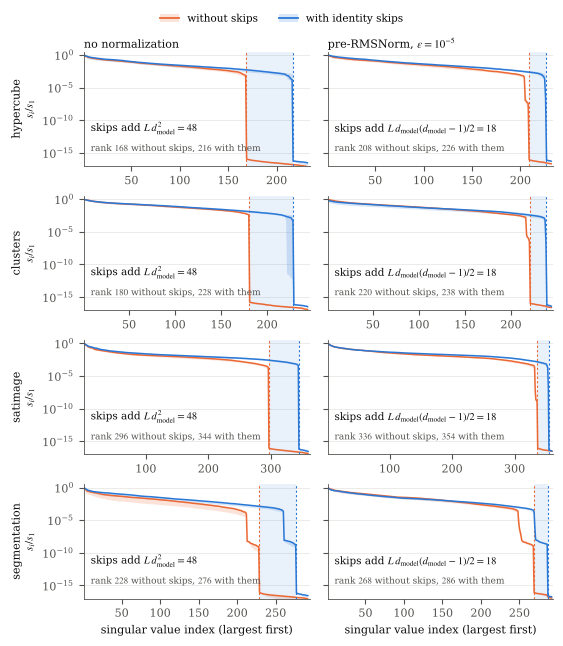

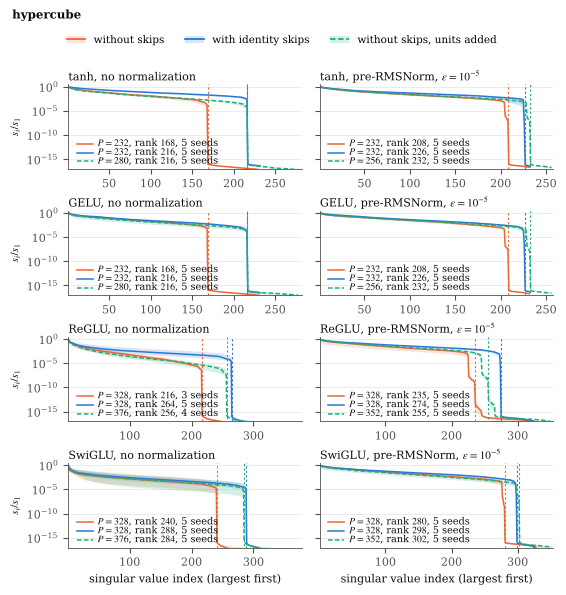

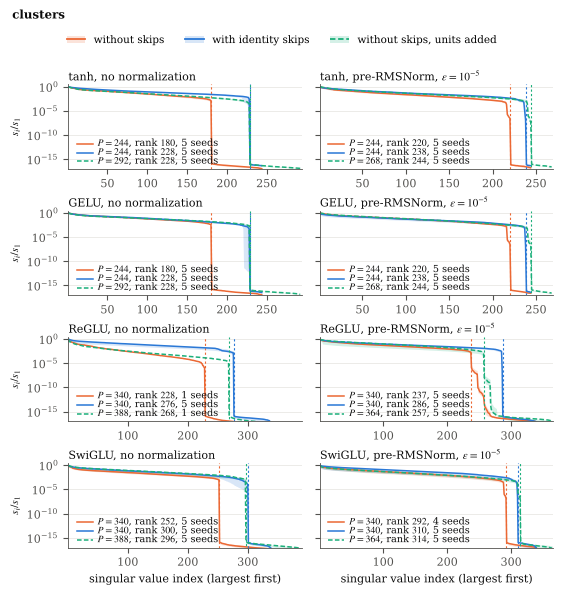

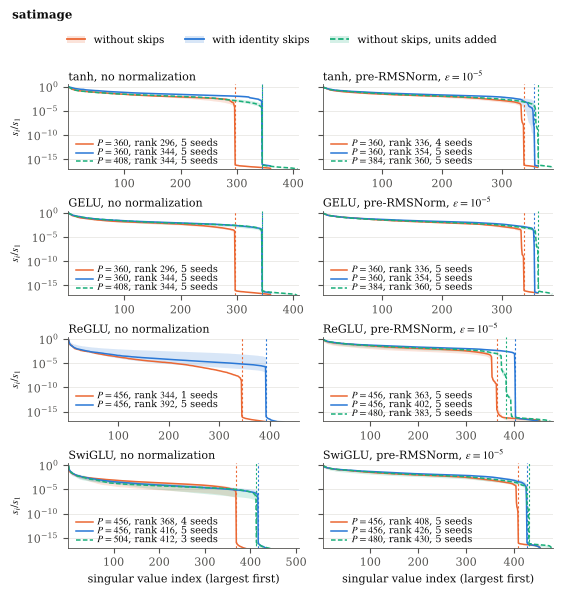

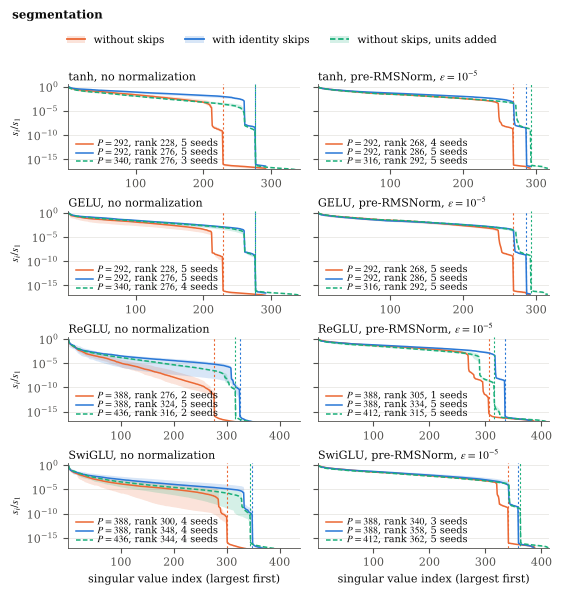

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

blue, orange, aqua, ink, muted, grid = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "DejaVu Serif"],
                     "mathtext.fontset": "stix", "font.size": 8, "axes.edgecolor": muted, "axes.labelcolor": ink,
                     "xtick.color": muted, "ytick.color": muted, "axes.linewidth": 0.6})
NAMES = {"clusters": "clusters (scikit-learn)", "hypercube": "hypercube (scikit-learn)", "satimage": "satimage (PMLB)",
         "segmentation": "segmentation (PMLB)"}


def series(name, act, eps, kind, b="data"):
    # median, min and max over the trained seeds of log10 s_i/s_1, and the most common rank
    ks = [key(r) for r in runs if (r["dataset"], r["act"], r["eps"], r["kind"]) == (name, act, eps, kind)]
    if not ks:
        return None
    S = np.array([saved[f"{k}_{b}_logs"] for k in ks])
    R = Counter(int(saved[f"{k}_{b}_rank"]) for k in ks).most_common(1)[0][0]
    return np.median(S, 0), S.min(0), S.max(0), R, len(ks)


def panel(ax, name, act, eps, kinds, b="data"):
    cols = {"skip": blue, "noskip": orange, "wide": aqua}
    lss = {"skip": "solid", "noskip": "solid", "wide": (0, (3, 1.5))}
    rk = {}
    for kind in kinds:
        sr = series(name, act, eps, kind, b)
        if sr is None:
            continue
        med, lo, hi, R, n = sr
        idx = np.arange(1, len(med) + 1)
        ax.fill_between(idx, 10.0 ** lo, 10.0 ** hi, color=cols[kind], alpha=0.18, lw=0)
        ax.semilogy(idx, 10.0 ** med, color=cols[kind], lw=1.1, ls=lss[kind], solid_capstyle="round")
        ax.axvline(R + 0.5, color=cols[kind], lw=0.8, ls=(0, (2, 2)) if kind != "wide" else (2, (2, 2)))
        rk[kind] = (R, len(med), n)
    ax.set_ylim(1e-17, 3)
    ax.set_yticks([1e-15, 1e-10, 1e-5, 1])
    ax.grid(axis="y", color=grid, lw=0.5)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    return rk


def draw_gelu(path, b="data"):
    # Figure 1 at trained weights: GELU; rows: datasets; columns: no normalization and pre-RMSNorm
    H = 1.45 * len(DATASETS) + 0.55
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(5.5, H), sharey=True, squeeze=False)
    dm = r"d_{\mathrm{model}}"
    for i, name in enumerate(DATASETS):
        for j, eps in enumerate(NORMS):
            ax = axes[i, j]
            rk = panel(ax, name, "GELU", eps, ["noskip", "skip"], b)
            if "noskip" in rk and "skip" in rk:
                (r0, P, n0), (r1, _, n1) = rk["noskip"], rk["skip"]
                ax.axvspan(r0 + 0.5, r1 + 0.5, color=blue, alpha=0.10, lw=0)
                cnt = rf"L\,{dm}^2" if eps is None else rf"L\,{dm}({dm}-1)/2"
                ax.text(0.03, 0.30, rf"skips add ${cnt} = {r1 - r0}$", transform=ax.transAxes, color=ink,
                        fontsize=7.5)
                ax.text(0.03, 0.13, f"rank ${r0}$ without skips, ${r1}$ with them", transform=ax.transAxes,
                        color=muted, fontsize=6.5)
            else:
                P = max([v[1] for v in rk.values()] or [1])
                ax.text(0.03, 0.2, "networks not trained", transform=ax.transAxes, color=muted, fontsize=7)
            if i == 0:
                title = "no normalization" if eps is None else r"pre-RMSNorm, $\varepsilon = 10^{-5}$"
                ax.set_title(title, fontsize=8, color=ink, loc="left", pad=3)
            ax.set_xlim(1, P + 2)
            if i == len(DATASETS) - 1:
                ax.set_xlabel("singular value index (largest first)")
        axes[i, 0].set_ylabel(f"{name}\n" + r"$s_i/s_1$")
    handles = [(Patch(color=c, alpha=0.18, lw=0), Line2D([], [], color=c, lw=1.3)) for c in (orange, blue)]
    fig.legend(handles, ["without skips", "with identity skips"], handler_map={tuple: HandlerTuple(ndivide=1)},
               loc="upper center", ncol=2, frameon=False, fontsize=7.5, handlelength=1.8, bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(pad=0.3, w_pad=1.2, h_pad=0.6, rect=(0, 0, 1, 1 - 0.3 / H))
    fig.savefig(path); fig.savefig(path.with_suffix(".png"), dpi=200)
    print("wrote", path)
    return fig


def draw_all(name, path, b="data"):
    # Figure 4 at trained weights for one dataset: rows = activations, columns = normalization
    fig, axes = plt.subplots(len(ACTS), 2, figsize=(5.5, 5.8), sharey=True, squeeze=False)
    for i, act in enumerate(ACTS):
        for j, eps in enumerate(NORMS):
            ax = axes[i, j]
            rk = panel(ax, name, act, eps, ["noskip", "skip", "wide"], b)
            for n, kind in enumerate(["noskip", "skip", "wide"]):
                if kind in rk:
                    R, P, ns = rk[kind]
                    y = 0.30 - 0.105 * n
                    c = {"skip": blue, "noskip": orange, "wide": aqua}[kind]
                    ax.plot([0.035, 0.105], [y, y], transform=ax.transAxes, color=c, lw=1.1,
                            ls="solid" if kind != "wide" else (0, (3, 1.5)))
                    ax.text(0.125, y, f"$P = {P}$, rank ${R}$, {ns} seeds", transform=ax.transAxes, va="center",
                            color=ink, fontsize=7)
            if rk:
                ax.set_xlim(1, max(v[1] for v in rk.values()) + 2)
            title = "no normalization" if eps is None else r"pre-RMSNorm, $\varepsilon = 10^{-5}$"
            ax.set_title(f"{act}, {title}", fontsize=8, color=ink, loc="left", pad=3)
            if i == len(ACTS) - 1:
                ax.set_xlabel("singular value index (largest first)")
        axes[i, 0].set_ylabel(r"$s_i/s_1$")
    handles = [(Patch(color=c, alpha=0.18, lw=0), Line2D([], [], color=c, lw=1.3, ls=ls))
               for c, ls in ((orange, "solid"), (blue, "solid"), (aqua, (0, (3, 1.5))))]
    fig.legend(handles, ["without skips", "with identity skips", "without skips, units added"],
               handler_map={tuple: HandlerTuple(ndivide=1)}, loc="upper center", ncol=3, frameon=False, fontsize=7.5,
               handlelength=1.8, bbox_to_anchor=(0.5, 0.97))
    fig.suptitle(name, x=0.01, y=0.998, ha="left", va="top", fontsize=8.5, color=ink, fontweight="bold")
    fig.tight_layout(pad=0.3, w_pad=1.2, h_pad=0.6, rect=(0, 0, 1, 0.925))
    fig.savefig(path); fig.savefig(path.with_suffix(".png"), dpi=200)
    print("wrote", path)
    return fig


figs = sn.RESULTS / "figs"
figs.mkdir(exist_ok=True)
draw_gelu(figs / "spectra_trained_gelu.pdf")
for name in DATASETS:
    draw_all(name, figs / f"spectra_trained_{name}.pdf")